## Finding best threshold for the model

In [4]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

TARGET = "Machine failure"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Features:", X.shape)
print("Target:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features: (10000, 6)
Target: (10000,)

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [5]:
X = pd.get_dummies(
    X,
    columns=["Type"],
    dtype=int
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 8)
Testing features: (2000, 8)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

# Split the original training set into training and validation
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train,
)

print("Training:", X_train_final.shape, y_train_final.sum(), "failures")
print("Validation:", X_val.shape, y_val.sum(), "failures")
print("Test:", X_test.shape, y_test.sum(), "failures")

Training: (6400, 8) 217 failures
Validation: (1600, 8) 54 failures
Test: (2000, 8) 68 failures


In [14]:
# Rename columns to XGBoost-compatible names
column_mapping = {
    "Air temperature [K]": "air_temperature",
    "Process temperature [K]": "process_temperature",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
}

X_train_final = X_train_final.rename(columns=column_mapping)
X_test = X_test.rename(columns=column_mapping)

print("Training columns:")
print(X_train.columns.tolist())

Training columns:
['air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear', 'Type_H', 'Type_L', 'Type_M']


In [15]:
from xgboost import XGBClassifier

model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,
    random_state=42,
    n_jobs=-1,
)

model.fit(X_train_final, y_train_final)

# Validation probabilities for threshold selection
val_prob = model.predict_proba(X_val)[:, 1]

print("Model trained. Validation probabilities generated.")

Model trained. Validation probabilities generated.


In [16]:
val_prob

array([0.00035296, 0.02933755, 0.00028793, ..., 0.00052971, 0.00088071,
       0.00105184], shape=(1600,), dtype=float32)

In [17]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score,
)

thresholds = np.arange(0.05, 0.81, 0.01)
results = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(y_val, val_pred, zero_division=0),
        "false_alarms": fp,
        "missed_failures": fn,
        "detected_failures": tp,
    })

threshold_results = pd.DataFrame(results)

eligible = threshold_results[
    threshold_results["recall"] >= 0.80
]

if eligible.empty:
    print("No threshold meets the 80% recall target.")
else:
    best = eligible.sort_values(
        ["precision", "threshold"],
        ascending=[False, False],
    ).iloc[0]

    selected_threshold = float(best["threshold"])

    print("Selected validation threshold:", round(selected_threshold, 2))
    print(best)

Selected validation threshold: 0.09
threshold             0.090000
precision             0.448980
recall                0.814815
f1                    0.578947
false_alarms         54.000000
missed_failures      10.000000
detected_failures    44.000000
Name: 4, dtype: float64


Selected threshold: 0.09
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.48      0.85      0.61        68

    accuracy                           0.96      2000
   macro avg       0.74      0.91      0.80      2000
weighted avg       0.98      0.96      0.97      2000

Test PR-AUC: 0.8154


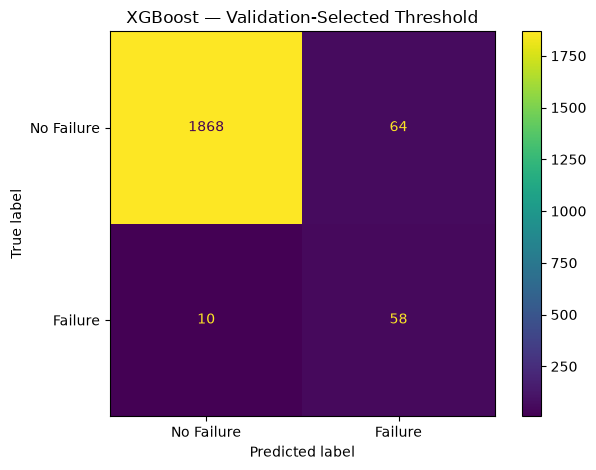

In [18]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)

print("Selected threshold:", round(selected_threshold, 3))
print(classification_report(y_test, test_pred, zero_division=0))
print(
    "Test PR-AUC:",
    round(average_precision_score(y_test, test_prob), 4),
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No Failure", "Failure"],
    values_format="d",
)
plt.title("XGBoost — Validation-Selected Threshold")
plt.tight_layout()
plt.show()

## experiment to test right prediction 

In [19]:

from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

# Calculate weight using training data only
negative_count = (y_train_final == 0).sum()
positive_count = (y_train_final == 1).sum()

positive_weight = negative_count / positive_count

print("Positive class weight:", round(positive_weight, 2))

weighted_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=positive_weight,
    random_state=42,
    n_jobs=-1,
)

weighted_model.fit(X_train_final, y_train_final)

weighted_val_prob = weighted_model.predict_proba(X_val)[:, 1]

print(
    "Weighted model validation PR-AUC:",
    round(
        average_precision_score(y_val, weighted_val_prob),
        4,
    ),
)


Positive class weight: 28.49
Weighted model validation PR-AUC: 0.7805


In [20]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

thresholds = np.arange(0.05, 0.81, 0.01)
results = []

for threshold in thresholds:
    val_pred = (weighted_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_pred,
        labels=[0, 1],
    ).ravel()

    results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "false_alarms": fp,
        "missed_failures": fn,
        "detected_failures": tp,
    })

weighted_results = pd.DataFrame(results)

# Keep thresholds that meet our provisional recall target
eligible = weighted_results[
    weighted_results["recall"] >= 0.80
]

eligible.sort_values(
    ["precision", "threshold"],
    ascending=[False, False],
).head(10)

,threshold,precision,recall,f1,false_alarms,missed_failures,detected_failures
34,0.39,0.415094,0.814815,0.550000,62,10,44
33,0.38,0.403670,0.814815,0.539877,65,10,44
32,0.37,0.403670,0.814815,0.539877,65,10,44
31,0.36,0.396396,0.814815,0.533333,67,10,44
30,0.35,0.389381,0.814815,0.526946,69,10,44
29,0.34,0.385965,0.814815,0.523810,70,10,44
28,0.33,0.379310,0.814815,0.517647,72,10,44
26,0.31,0.375000,0.833333,0.517241,75,9,45
25,0.30,0.373984,0.851852,0.519774,77,8,46
27,0.32,0.372881,0.814815,0.511628,74,10,44


In [21]:
from sklearn.metrics import average_precision_score

comparison = {
    "Baseline": {
        "PR-AUC": average_precision_score(y_val, val_prob),
    },
    "Class-weighted": {
        "PR-AUC": average_precision_score(y_val, weighted_val_prob),
    },
}

import pandas as pd

pd.DataFrame(comparison).T.round(4)

,PR-AUC
Baseline,0.7757
Class-weighted,0.7805
